# Don't Get Kicked — XGBoost *without* JDF (ablation) + Optuna

**Goal.** Measure what the `JointDistributionFilter` (JDF) contributes. The pipeline is the same as in the main XGBoost notebook, but the JDF step is removed and the XGBoost hyper-parameters are **re-tuned with Optuna (100 trials)**, because the optimum can move when the filter is gone.

## Pipeline
`Preprocessing` (feature engineering + stacked factors + binary text-token matrix) → `FeatureImportanceDropper` (drops the `n_worst` least important features from a pre-computed table `importance_df.csv`, attach it as a Kaggle dataset) → `XGBClassifier`.

Without the JDF nothing is filtered: rare and train-only categories stay in the data. XGBoost needs identical pandas categories in train/validation/test, so the helper `align_cats` takes the category set of the training part and turns unseen levels into NaN.

## Protocol
1. **Tuning** – fold 0 (train/valid), early stopping on valid ROC AUC, trial value = AUC at the best iteration; the best iteration of the best trial becomes the number of trees.
2. **Evaluation** – 5-fold CV with the tuned parameters (pipeline fitted inside every fold), out-of-fold ROC AUC and averaged test predictions (`submission.csv`).

In [ ]:
SEED, K = 42, 5
TRAIN_PATH = "../dont_get_kicked/datasets/training.csv"
TEST_PATH = "../dont_get_kicked/datasets/test.csv"
OUT_PATH = "xgb_no_jdf_kaggle_submission.csv"



IMPORTANCE_PATH = IMPORTANCE_PATH = "../importance_df.csv"    
DEVICE = "cpu"                                 
N_TRIALS, MAX_TREES, ES_ROUNDS = 100, 4000, 100

PREP = {"date_days": 14, "text_min_count_train": 100}
N_WORST = 200
JDF = {"dp": 0.02, "th_num_train": 0.001, "th_num_test": 0.001, "th_cat_train": 0.005, "th_cat_test": 0.005}  # only for the comparison
COMPARE_WITH_JDF = True

## Code: preprocessing classes (copied from the project)

In [2]:
import re
from collections import Counter
from typing import Optional

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import json

import optuna
import xgboost as xgb

MMR_COLS = ['MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']
NUMER_COLS = MMR_COLS + ['WarrantyCost', 'VehBCost']
CAT_COLS = ['Auction', 'BYRNO', 'VNZIP1', 'VNST', 'VehYear', 'Make', 'Model', 'Trim', 'SubModel', 'WheelType', 'Size', 'Color', 'PRIMEUNIT']
TEXT_COLS = ['Make', 'Model', 'Trim', 'SubModel']
DEFAULT_JDF_NUM_COLS = ['WarrantyCost', 'VehBCost', 'REL_DRIFT_RET_CLEAN', 'REL_DRIFT_RET_AVG', 'REL_DRIFT_AUC_AVG', 'REL_WarrantyCost', 'REL_VehBCost', 'VehOdo', 'VEHODO/VEHICLEAGE']
DEFAULT_JDF_CAT_COLS = list(CAT_COLS)
TOKEN_RE = re.compile('[a-z0-9]+')
PURCH_DATE_ORIGIN = pd.Timestamp('2009-01-05')

class Preprocessing(BaseEstimator, TransformerMixin):

    def __init__(self, mmr_cols: Optional[list]=None, numer_cols: Optional[list]=None, cat_cols: Optional[list]=None, text_cols: Optional[list]=None, price_trash_threshold: float=100.0, cramer_v_min: float=0.5, price_pipeline_degree: int=3, price_pipeline_alpha: float=0.007, text_min_count_train: int=100, text_logreg_C: float=65.0, add_text_binary_matrix: bool=False, date_pipeline_degree: int=13, date_pipeline_alpha: float=0.007, date_days: int=14, min_flag_count: int=500, weekday_type: Optional[str]=None):
        self.mmr_cols = list(mmr_cols) if mmr_cols is not None else list(MMR_COLS)
        self.numer_cols = list(numer_cols) if numer_cols is not None else list(NUMER_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(CAT_COLS)
        self.text_cols = list(text_cols) if text_cols is not None else list(TEXT_COLS)
        self.price_trash_threshold = price_trash_threshold
        self.cramer_v_min = cramer_v_min
        self.price_pipeline_degree = price_pipeline_degree
        self.price_pipeline_alpha = price_pipeline_alpha
        self.text_min_count_train = text_min_count_train
        self.text_logreg_C = text_logreg_C
        self.add_text_binary_matrix = add_text_binary_matrix
        self.date_pipeline_degree = date_pipeline_degree
        self.date_pipeline_alpha = date_pipeline_alpha
        self.date_days = date_days
        self.min_flag_count = min_flag_count
        self.weekday_type = weekday_type
        self.numer_cols_means = {}
        self.text_vocab = set()
        self.text_model = None
        self.text_vector_names = []
        self.price_pipeline = None
        self.date_ppl = None
        self.trash_flag_cols = []

    @staticmethod
    def _cramers_v(x, y):
        x = np.asarray(x)
        y = np.asarray(y)
        confusion = pd.crosstab(x, y)
        try:
            from scipy.stats import chi2_contingency
            chi2, _, _, _ = chi2_contingency(confusion.values)
        except Exception:
            chi2 = 0.0
        n = confusion.values.sum()
        phi2 = chi2 / n
        r, k = confusion.shape
        phi2corr = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
        rcorr = r - (r - 1) ** 2 / (n - 1)
        kcorr = k - (k - 1) ** 2 / (n - 1)
        denom = min(kcorr - 1, rcorr - 1)
        if denom <= 0:
            return 0.0
        return np.sqrt(phi2corr / denom)

    @staticmethod
    def _build_text(X):
        return (X['Make'].fillna('').astype(str) + ' ' + X['Model'].fillna('').astype(str) + ' ' + X['Trim'].fillna('').astype(str) + ' ' + X['SubModel'].fillna('').astype(str)).str.lower()

    @classmethod
    def _token_lists(cls, X):
        text = cls._build_text(X)
        return text.map(lambda s: list(dict.fromkeys(TOKEN_RE.findall(s)))).tolist()

    def _token_matrix(self, token_lists):
        index = {t: j for j, t in enumerate(self.text_vector_names)}
        matrix = np.zeros((len(token_lists), len(index)), dtype=np.uint8)
        for i, toks in enumerate(token_lists):
            for t in toks:
                j = index.get(t)
                if j is not None:
                    matrix[i, j] = 1
        return matrix

    def _trash_mask(self, s):
        return (s < self.price_trash_threshold) | s.isna()

    def _clean_numeric(self, X):
        X_num = X[self.numer_cols].copy().astype(float)
        for col in self.numer_cols:
            X_num.loc[self._trash_mask(X_num[col]), col] = self.numer_cols_means[col]
        return X_num

    def _date_frame(self, X):
        return pd.DataFrame({'PurchDate': (X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)})

    def _fill_cat_none(self, X):
        for col in self.cat_cols:
            if col in X.columns:
                X[col] = X[col].fillna('init_None').astype(str)
        return X

    def fit(self, X, y):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        y_arr = y.values.astype(float) if hasattr(y, 'values') else np.asarray(y, dtype=float)
        self.numer_cols_means = {}
        for col in self.numer_cols:
            self.numer_cols_means[col] = X.loc[~self._trash_mask(X[col]), col].mean()
        trash_flags = {f'{col}_is_trash': self._trash_mask(X[col]).astype(int) for col in self.numer_cols}
        flag_cols = list(trash_flags.keys())
        keep_flags = list(flag_cols)
        for i, c1 in enumerate(flag_cols):
            for c2 in flag_cols[i + 1:]:
                v = self._cramers_v(trash_flags[c1], trash_flags[c2])
                if v > self.cramer_v_min:
                    if trash_flags[c1].mean() < trash_flags[c2].mean():
                        if c1 in keep_flags:
                            keep_flags.remove(c1)
                    elif c2 in keep_flags:
                        keep_flags.remove(c2)
        for c in list(keep_flags):
            if trash_flags[c].sum() < self.min_flag_count:
                keep_flags.remove(c)
        self.trash_flag_cols = keep_flags
        X_num = self._clean_numeric(X)
        self.price_pipeline = Pipeline([('SS1', StandardScaler()), ('PT', PolynomialFeatures(self.price_pipeline_degree, include_bias=False)), ('SS2', StandardScaler()), ('LR', LogisticRegression(C=100, max_iter=10000))]).fit(X_num, y_arr)
        self.date_ppl = Pipeline([('ss1', StandardScaler()), ('pt', PolynomialFeatures(degree=self.date_pipeline_degree, include_bias=False)), ('ss2', StandardScaler()), ('lr', Ridge(alpha=self.date_pipeline_alpha))]).fit(self._date_frame(X), y_arr)
        Xp = self._fill_cat_none(X.copy())
        token_lists = self._token_lists(Xp)
        token_counts = Counter((t for toks in token_lists for t in toks))
        thr = self.text_min_count_train
        if isinstance(thr, float):
            thr = thr * len(Xp)
        self.text_vocab = {t for t, c in token_counts.items() if c >= thr}
        self.text_vector_names = sorted(self.text_vocab)
        if self.text_vector_names:
            token_matrix = self._token_matrix(token_lists)
            self.text_model = LogisticRegression(C=self.text_logreg_C, max_iter=5000)
            self.text_model.fit(token_matrix, y_arr)
        else:
            self.text_model = None
        return self

    def transform(self, X):
        X = X.copy()
        X['PurchDate'] = pd.to_datetime(X['PurchDate'])
        X = self._fill_cat_none(X)
        X_trans = self._clean_numeric(X)
        divisor = X_trans['MMRAcquisitionAuctionCleanPrice'].copy()
        X_trans['price_factor'] = self.price_pipeline.predict_proba(X_trans[self.numer_cols])[:, 1]
        for col in self.cat_cols:
            if col in X.columns:
                X_trans[col] = X[col]
        for col_base in self.numer_cols:
            flag_name = f'{col_base}_is_trash'
            if flag_name in self.trash_flag_cols:
                X_trans[flag_name] = self._trash_mask(X[col_base]).astype(int)
        token_matrix = None
        if self.text_vector_names:
            token_matrix = self._token_matrix(self._token_lists(X))
        if self.add_text_binary_matrix and token_matrix is not None:
            ohe_df = pd.DataFrame(token_matrix, columns=[f'text__{t}' for t in self.text_vector_names], index=X.index)
            X_trans = pd.concat([X_trans, ohe_df], axis=1)
        X_trans['REL_DRIFT_RET_CLEAN'] = (X_trans['MMRCurrentRetailCleanPrice'] - X_trans['MMRAcquisitonRetailCleanPrice']) / X_trans['MMRAcquisitonRetailCleanPrice']
        X_trans['REL_DRIFT_RET_AVG'] = (X_trans['MMRCurrentRetailAveragePrice'] - X_trans['MMRAcquisitionRetailAveragePrice']) / X_trans['MMRAcquisitionRetailAveragePrice']
        X_trans['REL_DRIFT_AUC_AVG'] = (X_trans['MMRCurrentAuctionAveragePrice'] - X_trans['MMRAcquisitionAuctionAveragePrice']) / X_trans['MMRAcquisitionAuctionAveragePrice']
        X_trans.drop(columns=self.numer_cols[:len(MMR_COLS)], inplace=True, errors='ignore')
        rel_cols = ['WarrantyCost', 'VehBCost']
        X_trans[['REL_' + col for col in rel_cols]] = X_trans[rel_cols].values / divisor.values.reshape(-1, 1)
        X_trans[['VehOdo', 'VehicleAge']] = X[['VehOdo', 'VehicleAge']]
        X_trans['VEHODO/VEHICLEAGE'] = X['VehOdo'] / (X['VehicleAge'] + 1)
        if self.text_model is not None and token_matrix is not None:
            X_trans['text_factor'] = self.text_model.predict_proba(token_matrix)[:, 1]
        X_trans['Date_factor'] = self.date_ppl.predict(self._date_frame(X))
        X_trans['date_days_count'] = ((X['PurchDate'] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)).astype('category')
        if self.weekday_type is not None:
            wd = X['PurchDate'].dt.weekday
            X_trans['weekday'] = wd.astype('category') if self.weekday_type == 'category' else wd.astype(float)
        for col in self.cat_cols:
            if col in X_trans.columns:
                X_trans[col] = X_trans[col].astype('category')
        return X_trans

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)
        return self.transform(X)

class JointDistributionFilter(TransformerMixin):

    def __init__(self, X_train, X_test=None, num_cols=None, cat_cols=None, dp: float=0.02, th_num_train: float=0.001, th_num_test: float=0.001, th_cat_train: float=0.005, th_cat_test: float=0.005, min_dx_frac: float=0.001, bin_prefix: str='text__', verbose: bool=False):
        self.dp = dp
        self.th_num_train = th_num_train
        self.th_num_test = th_num_test
        self.th_cat_train = th_cat_train
        self.th_cat_test = th_cat_test
        self.min_dx_frac = min_dx_frac
        self.bin_prefix = bin_prefix
        self.verbose = verbose
        self.num_cols = list(num_cols) if num_cols is not None else list(DEFAULT_JDF_NUM_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(DEFAULT_JDF_CAT_COLS)
        self.train_profiles = {}
        self.test_profiles = {}
        self.bin_train_freq = {}
        self.bin_test_freq = {}
        self.bin_cols_to_drop_ = []
        self._build_profiles(X_train, is_test=False)
        if X_test is not None:
            self._build_profiles(X_test, is_test=True)
        self._build_bin_freqs(X_train, X_test)

    def _num_profile(self, s):
        x = pd.to_numeric(s, errors='coerce').dropna()
        n = len(x)
        if n == 0:
            return None
        shares = x.value_counts(normalize=True)
        heavy = shares[shares >= self.dp]
        heavy_shares = heavy.to_dict()
        rest = x[~x.isin(heavy.index)].values
        profile = {'heavy': heavy_shares, 'cx': None, 'log_cy': None}
        if len(rest) < 2:
            return profile
        rng = rest.max() - rest.min()
        if rng <= 0:
            return profile
        n_bins = int(round(1 / self.dp))
        edges = np.quantile(rest, np.linspace(0, 1, n_bins + 1))
        dx = np.maximum(np.diff(edges), self.min_dx_frac * rng)
        dens = 1.0 / n_bins / dx * rng
        centers = (edges[:-1] + edges[1:]) / 2.0
        cx = np.concatenate([[edges[0]], centers, [edges[-1]]])
        cy = np.concatenate([[dens[0]], dens, [dens[-1]]])
        profile['cx'], profile['log_cy'] = (cx, np.log(cy))
        return profile

    def _build_profiles(self, df, is_test: bool=False):
        profiles = {}
        for col in self.num_cols:
            if col in df.columns:
                p = self._num_profile(df[col])
                if p is not None:
                    profiles[col] = p
        for col in self.cat_cols:
            if col in df.columns:
                profiles[col] = df[col].value_counts(normalize=True).to_dict()
        if is_test:
            self.test_profiles = profiles
        else:
            self.train_profiles = profiles

    def _build_bin_freqs(self, X_train, X_test=None):
        bin_cols = [c for c in X_train.columns if str(c).startswith(self.bin_prefix)]
        self.bin_train_freq = {c: float(pd.to_numeric(X_train[c], errors='coerce').fillna(0).mean()) for c in bin_cols}
        self.bin_test_freq = {}
        if X_test is not None:
            self.bin_test_freq = {c: float(pd.to_numeric(X_test[c], errors='coerce').fillna(0).mean()) for c in bin_cols if c in X_test.columns}
        drop = []
        for c in bin_cols:
            if self.bin_train_freq[c] < self.th_cat_train:
                drop.append(c)
            elif X_test is not None and self.bin_test_freq.get(c, 0.0) < self.th_cat_test:
                drop.append(c)
        self.bin_cols_to_drop_ = drop
        if self.verbose:
            print(f'binary {self.bin_prefix}* columns: dropping {len(drop)} of {len(bin_cols)}')

    @staticmethod
    def _num_pass_mask(x, profile, th_num, th_heavy):
        if profile['cx'] is None:
            mask = np.zeros(len(x), dtype=bool)
        else:
            log_d = np.interp(x, profile['cx'], profile['log_cy'], left=-np.inf, right=-np.inf)
            mask = np.exp(log_d) >= th_num
        if profile['heavy']:
            share = pd.Series(x).map(profile['heavy']).values
            is_heavy = ~np.isnan(share)
            mask = np.where(is_heavy, np.nan_to_num(share) >= th_heavy, mask)
        return mask

    @staticmethod
    def _cat_share(values, profile):
        s = pd.Series(np.asarray(values, dtype=object))
        return s.map(profile).astype(float).fillna(0.0).values

    def _surviving_categories(self, col):
        cats = []
        test_profile = self.test_profiles.get(col)
        for k, share in self.train_profiles[col].items():
            if share < self.th_cat_train or share <= 0:
                continue
            if test_profile is not None and test_profile.get(k, 0.0) < self.th_cat_test:
                continue
            cats.append(k)
        return cats

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.num_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            x = pd.to_numeric(X_out[col], errors='coerce').astype(float).values
            final = self._num_pass_mask(x, self.train_profiles[col], self.th_num_train, self.th_cat_train)
            if col in self.test_profiles:
                final &= self._num_pass_mask(x, self.test_profiles[col], self.th_num_test, self.th_cat_test)
            was_nan = np.isnan(x)
            out = x.copy()
            out[~final] = np.nan
            X_out[col] = out
            if self.verbose:
                print(f'{col}: masked {(~final & ~was_nan).mean():.2%} of values')
        for col in self.cat_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            vals = X_out[col].values
            final = self._cat_share(vals, self.train_profiles[col]) >= self.th_cat_train
            if col in self.test_profiles:
                final &= self._cat_share(vals, self.test_profiles[col]) >= self.th_cat_test
            cats = self._surviving_categories(col)
            X_out[col] = pd.Series(np.asarray(X_out[col].values, dtype=object), index=X_out.index).where(final).astype(pd.CategoricalDtype(categories=cats))
            if self.verbose:
                print(f'{col}: masked {(~final).mean():.2%} of values')
        drop_cols = [c for c in self.bin_cols_to_drop_ if c in X_out.columns]
        if drop_cols:
            X_out = X_out.drop(columns=drop_cols)
        return X_out

class FeatureImportanceDropper(BaseEstimator, TransformerMixin):

    def __init__(self, importance_path: str='D:/DS_Proj/importance_df.csv', n_worst: int=170, n_best=None):
        self.importance_path = importance_path
        self.n_worst = n_worst
        self.n_best = n_best

    def fit(self, X: pd.DataFrame, y=None):
        imp = pd.read_csv(self.importance_path)
        imp = imp.loc[:, ['Feature', 'Importance']]
        imp = imp.sort_values('Importance', ascending=True).reset_index(drop=True)
        self.features_to_drop_ = imp['Feature'].iloc[:self.n_worst].tolist() + (imp['Feature'].iloc[-self.n_best:].tolist() if self.n_best else [])
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        cols = [c for c in self.features_to_drop_ if c in X.columns]
        return X.drop(columns=cols)

## Data

In [3]:
train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
train["PurchDate"], test["PurchDate"] = pd.to_datetime(train["PurchDate"]), pd.to_datetime(test["PurchDate"])
y = train["IsBadBuy"]
X, X_test, ref_id = train.drop(columns=["IsBadBuy", "RefId"]), test.drop(columns=["RefId"]), test["RefId"]
folds = list(StratifiedKFold(K, shuffle=True, random_state=SEED).split(X, y))
print(X.shape, X_test.shape, "positive rate:", round(y.mean(), 4))

(72983, 32) (48707, 32) positive rate: 0.123


## Helpers: data preparation with / without the JDF

In [4]:
def drop_empty_cats(*frames):
    """Drop categorical columns left without any category after the JDF (all values became NaN)."""
    empty = [c for c in frames[0] if isinstance(frames[0][c].dtype, pd.CategoricalDtype) and len(frames[0][c].cat.categories) == 0]
    return [f.drop(columns=empty) for f in frames]

def align_cats(*frames):
    """Without the JDF every frame has its own pandas categories: use the train ones, unseen levels -> NaN."""
    out = [frames[0]]
    for d in frames[1:]:
        d = d.copy()
        for c in frames[0].columns:
            if isinstance(frames[0][c].dtype, pd.CategoricalDtype):
                d[c] = pd.Categorical(d[c].astype(object), categories=frames[0][c].cat.categories)
        out.append(d)
    return out

def make_data(tr, va, use_jdf):
    prep = Preprocessing(add_text_binary_matrix=True, **PREP).fit(X.iloc[tr], y.iloc[tr])
    Xtr, Xva, Xte = (prep.transform(d) for d in (X.iloc[tr], X.iloc[va], X_test))
    if use_jdf:
        jdf = JointDistributionFilter(Xtr, Xte, **JDF)
        Xtr, Xva, Xte = drop_empty_cats(*(jdf.transform(d) for d in (Xtr, Xva, Xte)))
    else:
        Xtr, Xva, Xte = align_cats(Xtr, Xva, Xte)
    fid = FeatureImportanceDropper(IMPORTANCE_PATH, n_worst=N_WORST).fit(Xtr)
    return [fid.transform(d) for d in (Xtr, Xva, Xte)]

def make_model(params, n_trees, **extra):
    return xgb.XGBClassifier(n_estimators=n_trees, tree_method="hist", device=DEVICE, enable_categorical=True,
                             eval_metric="auc", random_state=SEED, **params, **extra)

## Step 1: Optuna tuning of XGBoost on fold 0 (no JDF)

In [5]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
tr, va = folds[0]
A, B, _ = make_data(tr, va, use_jdf=False)
print("features:", A.shape[1])

def objective(trial):
    p = {"learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
         "max_depth": trial.suggest_int("max_depth", 3, 10),
         "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 50.0, log=True),
         "subsample": trial.suggest_float("subsample", 0.5, 1.0),
         "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
         "gamma": trial.suggest_float("gamma", 1e-8, 5.0, log=True),
         "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
         "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True)}
    m = make_model(p, MAX_TREES, early_stopping_rounds=ES_ROUNDS).fit(A, y.iloc[tr], eval_set=[(B, y.iloc[va])], verbose=False)
    trees = int(m.best_iteration) + 1
    trial.set_user_attr("trees", trees)
    return roc_auc_score(y.iloc[va], m.predict_proba(B, iteration_range=(0, trees))[:, 1])

log = lambda study, t: print(f"trial {t.number + 1}: best valid AUC so far {study.best_value:.5f}") if (t.number + 1) % 10 == 0 else None
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS, callbacks=[log])

BEST_PARAMS, BEST_TREES = study.best_trial.params, study.best_trial.user_attrs["trees"]
print("best valid AUC:", round(study.best_value, 5), "| trees:", BEST_TREES)
print(json.dumps(BEST_PARAMS, indent=2))

features: 69
trial 10: best valid AUC so far 0.79331
trial 20: best valid AUC so far 0.79331
trial 30: best valid AUC so far 0.79331
trial 40: best valid AUC so far 0.79410
trial 50: best valid AUC so far 0.79416
trial 60: best valid AUC so far 0.79416
trial 70: best valid AUC so far 0.79453
trial 80: best valid AUC so far 0.79460
trial 90: best valid AUC so far 0.79460
trial 100: best valid AUC so far 0.79460
best valid AUC: 0.7946 | trees: 1565
{
  "learning_rate": 0.010756377289454446,
  "max_depth": 6,
  "min_child_weight": 26.63330598780939,
  "subsample": 0.9255871518243018,
  "colsample_bytree": 0.3423735345354212,
  "gamma": 0.0038931115189492983,
  "reg_alpha": 0.2564770535426091,
  "reg_lambda": 4.122096579346717e-05
}


## Step 2: 5-fold CV with the tuned parameters (and optional comparison with the JDF)

In [ ]:
def run_cv(use_jdf):
    oof, pred = np.zeros(len(X)), np.zeros(len(X_test))
    for k, (tr, va) in enumerate(folds):
        Xtr, Xva, Xte = make_data(tr, va, use_jdf)
        model = make_model(BEST_PARAMS, BEST_TREES).fit(Xtr, y.iloc[tr])
        oof[va] = model.predict_proba(Xva)[:, 1]
        pred += model.predict_proba(Xte)[:, 1] / K
        print(f"  fold {k}: features={Xtr.shape[1]}, val AUC={roc_auc_score(y.iloc[va], oof[va]):.5f}")
    return oof, pred

print("without JDF"); oof_no, test_pred = run_cv(False)
results = {"no JDF": oof_no}
if COMPARE_WITH_JDF:
    print("with JDF"); results["with JDF (same params)"] = run_cv(True)[0]

pd.DataFrame({"RefId": ref_id, "IsBadBuy": test_pred}).to_csv(OUT_PATH, index=False)   # the no-JDF solution
fold_auc = lambda o: [roc_auc_score(y.iloc[va], o[va]) for _, va in folds]
summary = pd.DataFrame({n: {"OOF AUC": roc_auc_score(y, o), "mean fold AUC": np.mean(fold_auc(o)), "std fold AUC": np.std(fold_auc(o))}
                        for n, o in results.items()}).T.round(5)
summary

without JDF
  fold 0: features=69, val AUC=0.79460
  fold 1: features=70, val AUC=0.78496
  fold 2: features=70, val AUC=0.80041
  fold 3: features=72, val AUC=0.79279
  fold 4: features=69, val AUC=0.78856
with JDF (same parameters)
  fold 0: features=55, val AUC=0.79243
  fold 1: features=55, val AUC=0.78479
  fold 2: features=55, val AUC=0.80034
  fold 3: features=54, val AUC=0.79277
  fold 4: features=55, val AUC=0.78883


,OOF AUC,mean fold AUC,std fold AUC
no JDF (tuned here),0.79219,0.79226,0.00527
with JDF (same params),0.79175,0.79183,0.00514


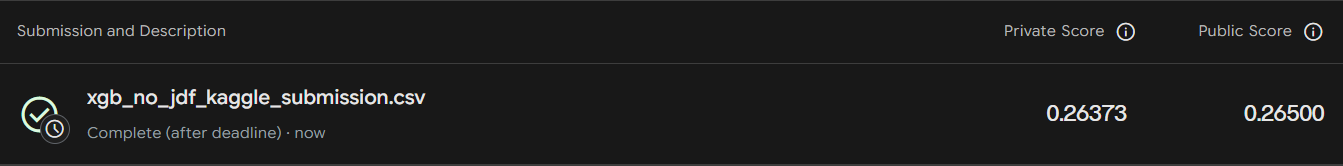

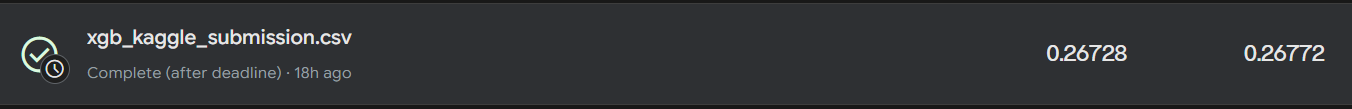

As can be seen from the results, JDF provides an improvement in both public and private scores.